# 05 · Six measured forecast illustrations
These are post-hoc **success illustrations**, selected using test targets. They are not a
random sample, not an estimate of typical improvement, and not used to train/select a predictor.
The `ttc4ts` column is the historical validation-selected method, whose actual deployed rule
is printed below. It must not be relabeled as the primary fixed Learned-weights method.


In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'artifacts/manifest.json').exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ttc4ts.results import (checked_path, load_snapshot, geometric, summarize,
    main_summary, lw_budget_summary, uncertainty_summary, MODELS, MODEL_LABELS, METHODS, METHOD_LABELS)
%matplotlib inline
plt.rcParams.update({'figure.dpi': 115, 'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
print('Offline mode: numerical snapshots are verified against the released SHA-256 manifest.')


Offline mode: numerical snapshots are verified against the released SHA-256 manifest.


In [2]:
manifest = json.loads(checked_path('examples/forecast_manifest.json').read_text())
print(manifest['selection_rule'])
metadata = pd.DataFrame(manifest['examples'])
display(metadata[['number','model','dataset','channel','forecast_start','deployment_method','frozen_mse','ttc4ts_mse','gain']])


Fixed six model/dataset pairs, H96, seed0; among origin/channel pairs with positive TTC4TS MSE reduction and TTC4TS MSE below half the target variance, select the order statistic nearest the 75th percentile of the reductions. Post-hoc illustrative success selection uses test targets; never used to fit or select a deployed predictor.


,number,model,dataset,channel,forecast_start,deployment_method,frozen_mse,ttc4ts_mse,gain
0,1,chronos-bolt-small,ETTh1,MUFL,2017-11-05 00:00:00,greedy,1.78880,1.37983,0.22863
1,2,chronos-bolt-base,ETTh2,MUFL,2018-02-09 00:00:00,validation_best,0.48568,0.44564,0.08243
2,3,timesfm-2.0-500m-pytorch,ETTm1,HUFL,2018-01-11 00:00:00,validation_best,0.53128,0.30128,0.43292
3,4,timer-base-84m,ETTm2,OT,2017-10-29 00:00:00,greedy,0.06198,0.03994,0.35565
4,5,sundial-base-128m,Appliances,T4,2016-05-23 16:20:00,greedy,0.01915,0.00735,0.61609
5,6,chronos-2,BeijingWeather,TEMP,2014-01-20 19:00:00,retrospective,0.06472,0.05479,0.15336


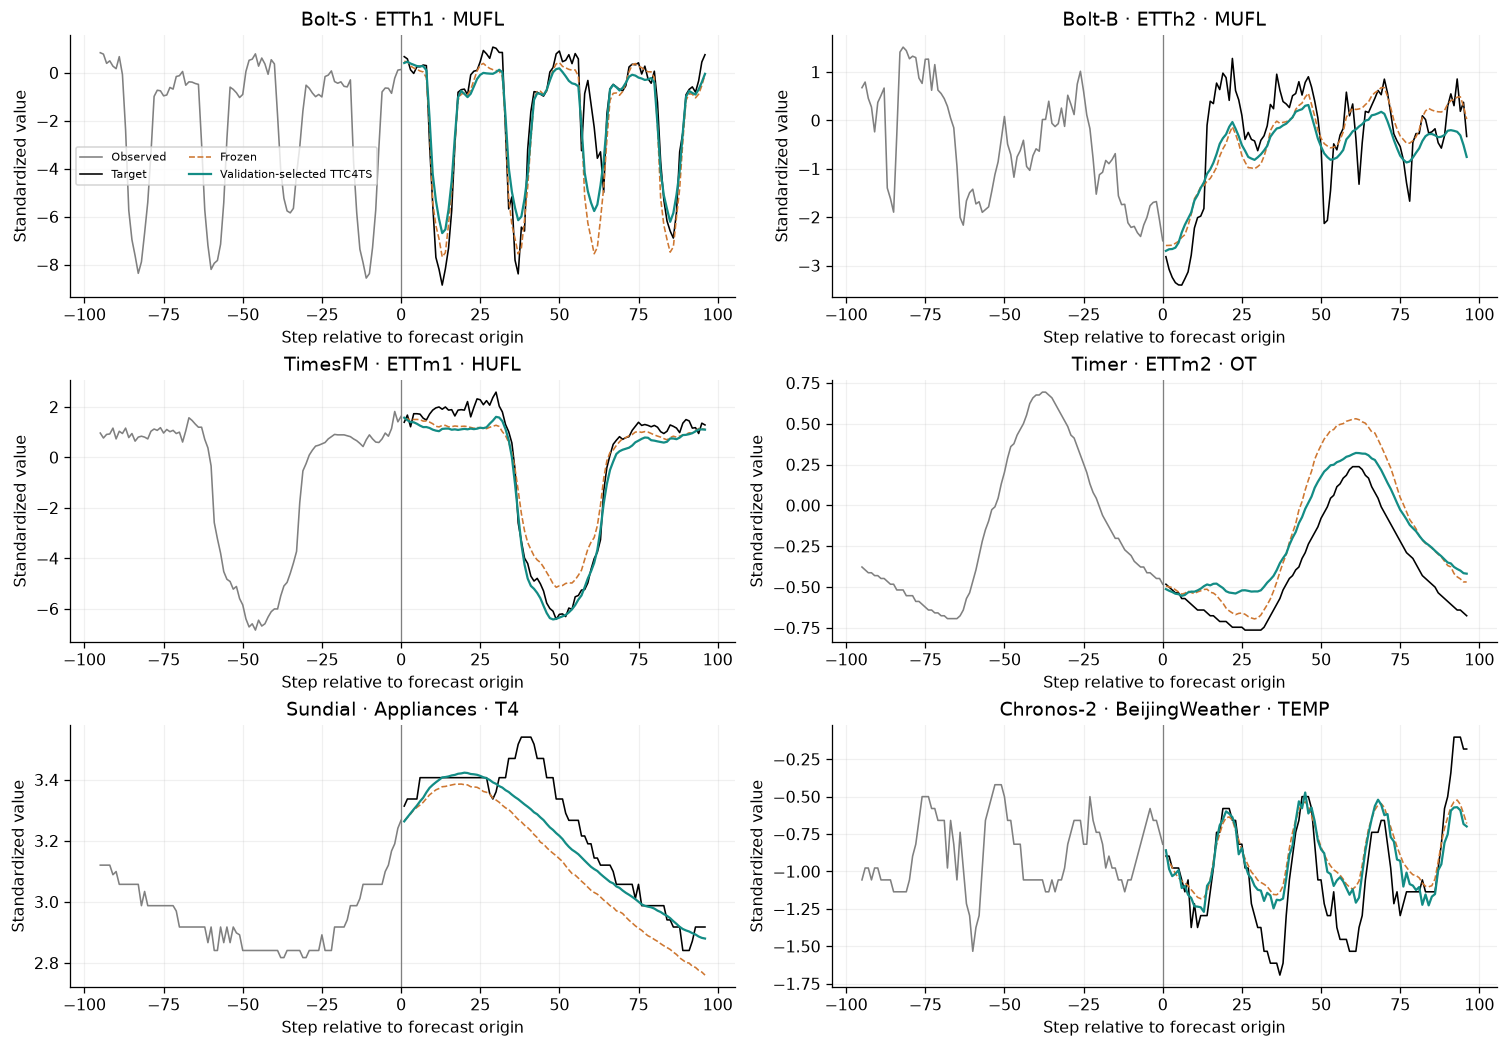

,example,frozen_mse,ttc4ts_mse,reduction
0,1,1.78880,1.37983,0.22863
1,2,0.48568,0.44564,0.08243
2,3,0.53128,0.30128,0.43292
3,4,0.06198,0.03994,0.35565
4,5,0.01915,0.00735,0.61609
5,6,0.06472,0.05479,0.15336


In [3]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9), layout='constrained')
checks = []
for ax, item in zip(axes.flat, manifest['examples']):
    n = item['number']
    future = pd.read_csv(checked_path(f'examples/forecast_{n}.csv'))
    history = pd.read_csv(checked_path(f'examples/forecast_{n}_history.csv'))
    mse = float(np.mean((future.ttc4ts-future.target)**2))
    frozen_mse = float(np.mean((future.frozen-future.target)**2))
    assert np.isclose(mse, item['ttc4ts_mse'], rtol=1e-6)
    assert np.isclose(frozen_mse, item['frozen_mse'], rtol=1e-6)
    checks.append(dict(example=n, frozen_mse=frozen_mse, ttc4ts_mse=mse, reduction=1-mse/frozen_mse))
    ax.plot(history.step, history.history, color='gray', lw=1, label='Observed')
    ax.plot(future.step, future.target, color='black', lw=1, label='Target')
    ax.plot(future.step, future.frozen, '--', color='#ce7731', lw=1, label='Frozen')
    ax.plot(future.step, future.ttc4ts, color='#138c85', lw=1.4, label='Validation-selected TTC4TS')
    ax.axvline(0, color='gray', lw=.8)
    ax.set(title=f"{MODEL_LABELS[item['model']]} · {item['dataset']} · {item['channel']}",
           xlabel='Step relative to forecast origin', ylabel='Standardized value')
axes[0,0].legend(fontsize=7, ncol=2); plt.show()
display(pd.DataFrame(checks))


Errors above are recomputed from the numeric forecast excerpts and checked against the
saved manifest. The excerpt conversion retained floating-point values and discarded object
date arrays; dates/origins/channel identities are supplied by the manifest. All source-file
digests are retained. Full paper-wide summary metrics are in notebook 01.
